# ChestScan AI — Classification des radiographies thoraciques

Ce notebook compare deux modèles pour classifier les images en **NORMAL** et **PNEUMONIA** :
1. un CNN construit from scratch ;
2. MobileNetV2 avec Transfer Learning.

> Ce projet est pédagogique. Il ne doit pas être utilisé pour établir un diagnostic médical.

## 1. Installer les dépendances

Exécute cette cellule si certaines bibliothèques ne sont pas installées.

In [1]:
%pip install -q kagglehub tensorflow numpy pandas matplotlib scikit-learn

## 2. Imports et configuration

In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

SEED = 42
IMG_SIZE_CNN = (180, 180)
IMG_SIZE_MOBILENET = (224, 224)
BATCH_SIZE = 32
EPOCHS_CNN = 15
EPOCHS_MOBILENET = 5
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]

tf.keras.utils.set_random_seed(SEED)

print("TensorFlow :", tf.__version__)
print("GPU disponible :", tf.config.list_physical_devices("GPU"))

TensorFlow : 2.21.0
GPU disponible : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Télécharger et localiser le dataset

Le dataset public est téléchargé via KaggleHub. Si Kaggle demande une authentification, configure tes identifiants Kaggle puis relance cette cellule.

In [ ]:
dataset_path = Path(
    kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
)
print("Chemin téléchargé :", dataset_path)

# Cherche un dossier qui contient train, val et test.
candidate_dirs = [dataset_path]
candidate_dirs.extend(dataset_path.rglob("chest_xray"))
candidate_dirs.extend(dataset_path.rglob("chest-xray-pneumonia"))

DATASET_ROOT = None
seen = set()

for folder in candidate_dirs:
    folder = Path(folder)
    if str(folder) in seen:
        continue
    seen.add(str(folder))
    if all((folder / split).is_dir() for split in ["train", "val", "test"]):
        DATASET_ROOT = folder
        break

if DATASET_ROOT is None:
    # Certains téléchargements ont un niveau supplémentaire de dossiers.
    for folder in dataset_path.rglob("*"):
        if folder.is_dir() and all(
            (folder / split).is_dir() for split in ["train", "val", "test"]
        ):
            DATASET_ROOT = folder
            break

if DATASET_ROOT is None:
    raise FileNotFoundError(
        f"Impossible de trouver les dossiers train/val/test dans {dataset_path}. "
        "Inspecte le chemin téléchargé et vérifie la structure du dataset."
    )

for split in ["train", "val", "test"]:
    for class_name in CLASS_NAMES:
        class_dir = DATASET_ROOT / split / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f"Dossier manquant : {class_dir}")

print("DATASET_ROOT =", DATASET_ROOT)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Chemin téléchargé : /kaggle/input/chest-xray-pneumonia
DATASET_ROOT = /kaggle/input/chest-xray-pneumonia/chest_xray


## 4. Explorer la distribution des images

In [4]:
extensions = {".jpeg", ".jpg", ".png"}
rows = []

for split in ["train", "val", "test"]:
    for class_name in CLASS_NAMES:
        folder = DATASET_ROOT / split / class_name
        count = sum(
            1 for file in folder.rglob("*")
            if file.is_file() and file.suffix.lower() in extensions
        )
        rows.append({
            "Split": split,
            "Classe": class_name,
            "Nombre d'images": count
        })

df_counts = pd.DataFrame(rows)
display(df_counts)
print("Total des images :", int(df_counts["Nombre d'images"].sum()))

,Split,Classe,Nombre d'images
0,train,NORMAL,1341
1,train,PNEUMONIA,3875
2,val,NORMAL,8
3,val,PNEUMONIA,8
4,test,NORMAL,234
5,test,PNEUMONIA,390


Total des images : 5856


## 5. Charger les datasets

Les labels sont 0 pour NORMAL et 1 pour PNEUMONIA. Les pixels restent en valeurs brutes ici : le CNN les normalise dans son modèle et MobileNetV2 utilise son propre prétraitement.

In [ ]:
def create_dataset(directory, image_size, shuffle):
    return keras.utils.image_dataset_from_directory(
        directory,
        labels="inferred",
        label_mode="binary",
        class_names=CLASS_NAMES,
        image_size=image_size,
        batch_size=BATCH_SIZE,
        color_mode="rgb",
        shuffle=shuffle,
        seed=SEED,
    )

train_ds_cnn = create_dataset(DATASET_ROOT / "train", IMG_SIZE_CNN, True)
val_ds_cnn = create_dataset(DATASET_ROOT / "val", IMG_SIZE_CNN, False)
test_ds_cnn = create_dataset(DATASET_ROOT / "test", IMG_SIZE_CNN, False)

train_ds_mobilenet = create_dataset(
    DATASET_ROOT / "train", IMG_SIZE_MOBILENET, True
)
val_ds_mobilenet = create_dataset(
    DATASET_ROOT / "val", IMG_SIZE_MOBILENET, False
)
test_ds_mobilenet = create_dataset(
    DATASET_ROOT / "test", IMG_SIZE_MOBILENET, False
)

AUTOTUNE = tf.data.AUTOTUNE
train_ds_cnn = train_ds_cnn.prefetch(AUTOTUNE)
val_ds_cnn = val_ds_cnn.prefetch(AUTOTUNE)
test_ds_cnn = test_ds_cnn.prefetch(AUTOTUNE)
train_ds_mobilenet = train_ds_mobilenet.prefetch(AUTOTUNE)
val_ds_mobilenet = val_ds_mobilenet.prefetch(AUTOTUNE)
test_ds_mobilenet = test_ds_mobilenet.prefetch(AUTOTUNE)

print("Classes :", CLASS_NAMES)

Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Found 5216 files belonging to 2 classes.
Found 16 files belonging to 2 classes.
Found 624 files belonging to 2 classes.
Classes : ['NORMAL', 'PNEUMONIA']


In [17]:
images, labels = next(iter(train_ds_cnn))
plt.figure(figsize=(12, 8))

print(images.shape)

(32, 180, 180, 3)


<Figure size 1200x800 with 0 Axes>

## 6. Visualiser quelques images

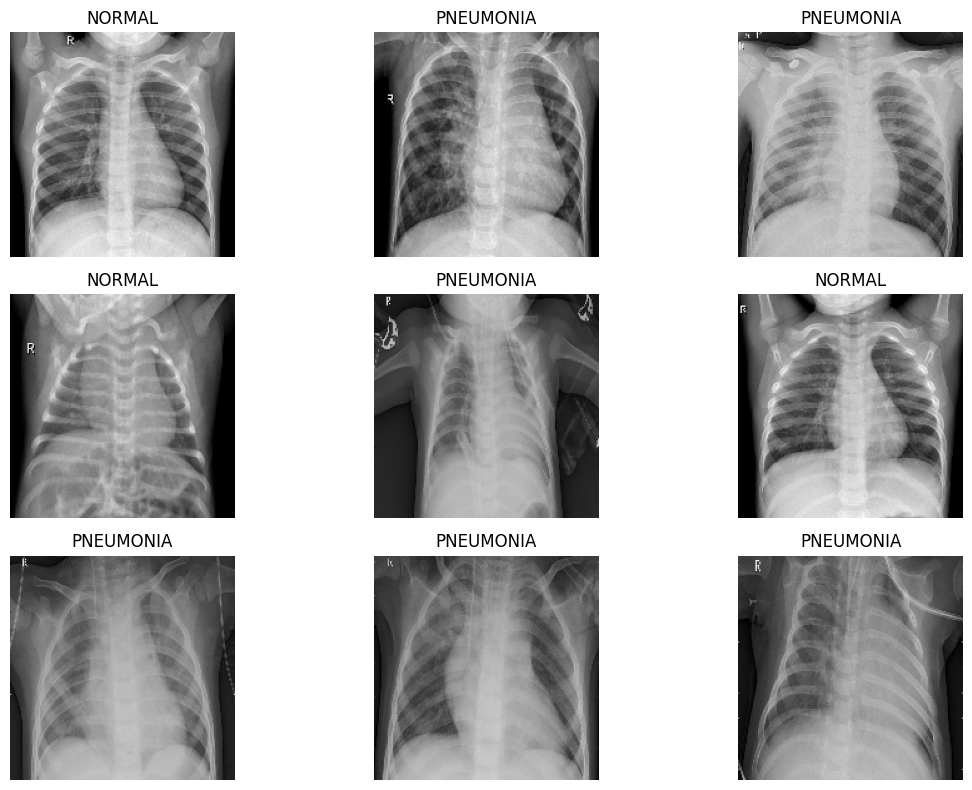

In [24]:
images, labels = next(iter(train_ds_cnn))
plt.figure(figsize=(12, 8))

for i in range(min(9, len(images))):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].numpy().astype("uint8"))
    plt.title(CLASS_NAMES[int(labels[i].numpy()[0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 7. Construire le CNN from scratch

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")

cnn_model = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE_CNN, 3)),
    data_augmentation,
    layers.Rescaling(1.0 / 255),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(1, activation="sigmoid"),
], name="CNN_From_Scratch")

cnn_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
cnn_model.summary()

Model: "CNN_From_Scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 180, 180, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 90, 90, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 90, 90, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 45, 45, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 30976)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │     3,965,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,988,769 (15.22 MB)

 Trainable params: 3,988,769 (15.22 MB)

 Non-trainable params: 0 (0.00 B)

## 8. Entraîner le CNN

In [8]:
os.makedirs("outputs", exist_ok=True)

cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "outputs/best_cnn.keras", monitor="val_loss", save_best_only=True
    ),
]

history_cnn = cnn_model.fit(
    train_ds_cnn,
    validation_data=val_ds_cnn,
    epochs=EPOCHS_CNN,
    callbacks=cnn_callbacks,
)

Epoch 1/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 49s 248ms/step - accuracy: 0.8071 - auc: 0.8198 - loss: 0.4326 - precision: 0.8239 - recall: 0.9417 - val_accuracy: 0.8750 - val_auc: 0.9219 - val_loss: 0.4407 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 2/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 30s 184ms/step - accuracy: 0.8980 - auc: 0.9526 - loss: 0.2406 - precision: 0.9218 - recall: 0.9427 - val_accuracy: 0.8750 - val_auc: 0.9375 - val_loss: 0.3330 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 3/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 29s 180ms/step - accuracy: 0.9243 - auc: 0.9675 - loss: 0.1992 - precision: 0.9466 - recall: 0.9517 - val_accuracy: 0.8125 - val_auc: 0.9688 - val_loss: 0.4303 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 4/15
163/163 ━━━━━━━━━━━━━━━━━━━━ 41s 180ms/step - accuracy: 0.9306 - auc: 0.9733 - loss: 0.1805 - precision: 0.9507 - recall: 0.9561 - val_accuracy: 0.8125 - val_auc: 0.9844 - val_loss: 0.4707 - val_precision: 0.7273 - val_recall: 1.0000
Epoch 5/15
163/163 ━

## 9. Visualiser l'entraînement du CNN

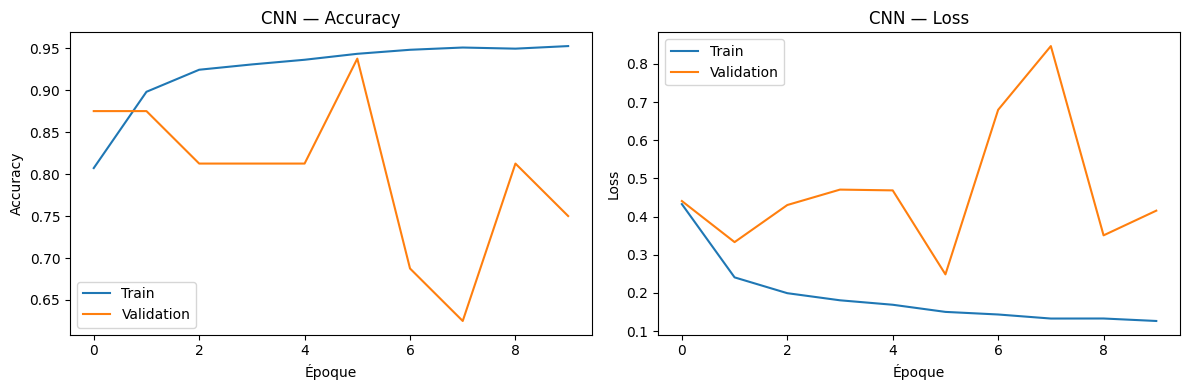

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_cnn.history["accuracy"], label="Train")
plt.plot(history_cnn.history["val_accuracy"], label="Validation")
plt.title("CNN — Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history["loss"], label="Train")
plt.plot(history_cnn.history["val_loss"], label="Validation")
plt.title("CNN — Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 10. Construire MobileNetV2 avec Transfer Learning

Les poids ImageNet de la base sont gelés pendant cette première phase. La tête de classification ajoutée apprend à distinguer les deux classes.

In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(*IMG_SIZE_MOBILENET, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE_MOBILENET, 3))
x = keras.applications.mobilenet_v2.preprocess_input(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

mobilenet_model = keras.Model(
    inputs, outputs, name="MobileNetV2_Transfer_Learning"
)

mobilenet_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ],
)
mobilenet_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "MobileNetV2_Transfer_Learning"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 11. Entraîner MobileNetV2

In [11]:
mobilenet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=2, restore_best_weights=True
    ),
    keras.callbacks.ModelCheckpoint(
        "outputs/best_mobilenet.keras",
        monitor="val_loss",
        save_best_only=True,
    ),
]

history_mobilenet = mobilenet_model.fit(
    train_ds_mobilenet,
    validation_data=val_ds_mobilenet,
    epochs=EPOCHS_MOBILENET,
    callbacks=mobilenet_callbacks,
)

Epoch 1/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 48s 219ms/step - accuracy: 0.8934 - auc: 0.9448 - loss: 0.2676 - precision: 0.9068 - recall: 0.9546 - val_accuracy: 0.8750 - val_auc: 0.9688 - val_loss: 0.2918 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 2/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 192ms/step - accuracy: 0.9540 - auc: 0.9870 - loss: 0.1369 - precision: 0.9652 - recall: 0.9732 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2547 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 3/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 31s 193ms/step - accuracy: 0.9611 - auc: 0.9907 - loss: 0.1120 - precision: 0.9722 - recall: 0.9755 - val_accuracy: 0.9375 - val_auc: 1.0000 - val_loss: 0.2118 - val_precision: 0.8889 - val_recall: 1.0000
Epoch 4/5
163/163 ━━━━━━━━━━━━━━━━━━━━ 40s 190ms/step - accuracy: 0.9666 - auc: 0.9932 - loss: 0.0965 - precision: 0.9756 - recall: 0.9796 - val_accuracy: 0.8750 - val_auc: 1.0000 - val_loss: 0.2383 - val_precision: 0.8000 - val_recall: 1.0000
Epoch 5/5
163/163 ━━━━━━

## 12. Visualiser l'entraînement de MobileNetV2

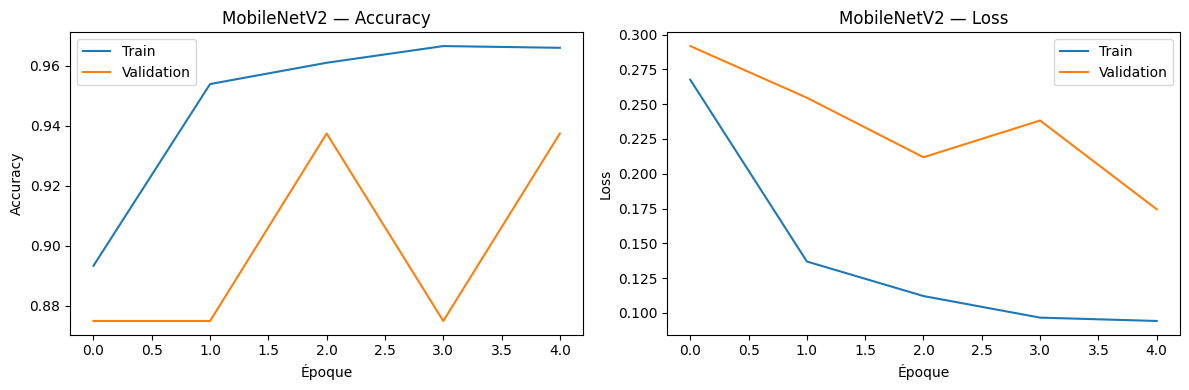

In [12]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_mobilenet.history["accuracy"], label="Train")
plt.plot(history_mobilenet.history["val_accuracy"], label="Validation")
plt.title("MobileNetV2 — Accuracy")
plt.xlabel("Époque")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_mobilenet.history["loss"], label="Train")
plt.plot(history_mobilenet.history["val_loss"], label="Validation")
plt.title("MobileNetV2 — Loss")
plt.xlabel("Époque")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 13. Évaluer et comparer les modèles

Les métriques sont calculées sur le jeu de test. Les prédictions positives correspondent à la classe PNEUMONIA.


===== CNN from scratch =====
              precision    recall  f1-score   support

      NORMAL       0.92      0.56      0.70       234
   PNEUMONIA       0.79      0.97      0.87       390

    accuracy                           0.82       624
   macro avg       0.85      0.77      0.78       624
weighted avg       0.84      0.82      0.80       624



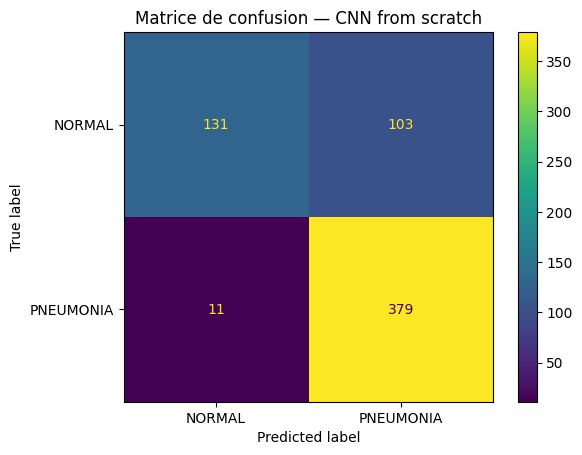


===== MobileNetV2 =====
              precision    recall  f1-score   support

      NORMAL       0.98      0.54      0.70       234
   PNEUMONIA       0.78      0.99      0.88       390

    accuracy                           0.82       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.86      0.82      0.81       624



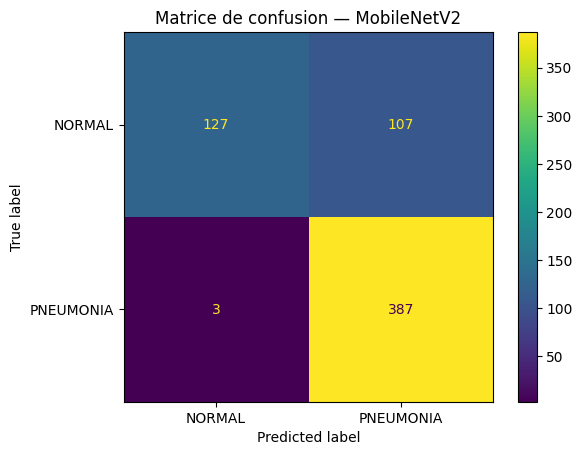

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modèle,,,,,
CNN from scratch,0.8173,0.7863,0.9718,0.8693,0.9478
MobileNetV2,0.8237,0.7834,0.9923,0.8756,0.9638


In [13]:
def evaluate_classifier(model, dataset, model_name):
    y_true = np.concatenate([
        labels.numpy().reshape(-1) for _, labels in dataset
    ]).astype(int)

    y_prob = model.predict(dataset, verbose=0).reshape(-1)
    y_pred = (y_prob >= 0.5).astype(int)

    result = {
        "Modèle": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

    print(f"\n===== {model_name} =====")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=CLASS_NAMES,
        zero_division=0,
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=CLASS_NAMES
    )
    display_cm.plot(values_format="d")
    plt.title(f"Matrice de confusion — {model_name}")
    plt.show()

    return result

results_cnn = evaluate_classifier(cnn_model, test_ds_cnn, "CNN from scratch")
results_mobilenet = evaluate_classifier(
    mobilenet_model, test_ds_mobilenet, "MobileNetV2"
)

comparison_df = pd.DataFrame([results_cnn, results_mobilenet]).set_index("Modèle")
display(comparison_df.round(4))

## 14. Sauvegarder les modèles et les résultats

In [ ]:
from pathlib import Path
import json

Path("outputs").mkdir(exist_ok=True)

cnn_model.save("outputs/cnn.keras")
mobilenet_model.save("outputs/mobilenetv2.keras")

metrics = {
    "CNN": results_cnn,
    "MobileNetV2": results_mobilenet
}

for model in metrics.values():
    model.pop("Modèle", None)

with open("outputs/metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4, ensure_ascii=False)

print("Fichiers sauvegardes :", list(Path("outputs").iterdir()))

Sauvegardes créées dans le dossier outputs/.
Fichiers : ['best_cnn.keras', 'best_mobilenet.keras', 'cnn_from_scratch.keras', 'mobilenetv2_transfer_learning.keras', 'model_comparison.csv', 'model_metrics.json']
